In [8]:
# File created for Bi-level optimization in MLP


import jax
import jax.numpy as jnp
from jax import random
from jax import grad, jit, vmap

import mlp_helpers as mh
import pade_ac as paf
from functools import partial


import matplotlib.pyplot as plt

size = [1,8,8,1]

key_params = random.PRNGKey(0)
key_coeffs = random.PRNGKey(5)

params = mh.init_network_params(size, key_params)
coeffs = mh.init_coeffs(size, n_coeffs=5, key=key_coeffs)
coeffs_init = coeffs


#INIT

input = jnp.linspace(0, 10, 100).reshape(-1, 1)

output = jax.random.uniform(jax.random.key(1), (100, 1))*0.5 + jnp.sin(input)
output = output/jnp.max(output)

x_train, y_train, x_val, y_val, x_test, y_test = mh.train_val_test_split(input, output)

lrp = 0.005
lrc = 0.005
n_int = 500
inner_steps = 20
batch_size = 64

key = random.PRNGKey(0)

# for epoch in range(n_int):
#     key, subkey = random.split(key)

#     for xb, yb in mh.make_batches(x_train, y_train, batch_size, key=subkey):
#         params, coeffs = mh.update_val_bilevel(params,coeffs ,xb, x_val, yb, y_val, lrp, lrc, inner_steps)
#     if epoch % 100 == 0:
#         print(f"Step {epoch}, Train Loss: {mh.loss(params,coeffs,x_train, y_train):.6f}, Val Loss: {mh.loss(params,coeffs,x_val, y_val):.6f}")

# # for epoch in range(n_int):
# #     key, subkey = random.split(key)

# #     for xb, yb in mh.make_batches(input, output, batch_size, key=subkey):
# #         params, coeffs = mh.update_non_val_bilevel(params,coeffs ,xb, yb, lrp, lrc, inner_steps)
# #     if epoch % 100 == 0:
# #         print(f"Step {epoch}, Train Loss: {mh.loss(params,coeffs,x_train, y_train):.6f}, Val Loss: {mh.loss(params,coeffs,x_val, y_val):.6f}")



def plot_used_activations(coeffs, x_min=-5, x_max=5, n_points=500):
    xs = jnp.linspace(x_min, x_max, n_points)

    for layer_idx, layer_coeffs in enumerate(coeffs[1:], start=1):
        plt.figure(figsize=(7, 4))

        for neuron_idx, c in enumerate(layer_coeffs):
            ys = paf.pade(xs, c)
            plt.plot(xs, ys, label=f"neurônio {neuron_idx}")

        plt.title(f"Funções de ativação usadas - camada {layer_idx}")
        plt.xlabel("x")
        plt.ylabel("pade(x, coeff)")
        plt.legend()
        plt.grid(True)
        plt.show()




In [2]:
coeffs = mh.init_coeffs(size, n_coeffs=5, key=key_coeffs)

def v_restriction(lower_coeffs):
    """
    Function that restricts the position of verticie
    """
    return (lower_coeffs[0]**2 -4*lower_coeffs[1])/(4*lower_coeffs[1])


@jit
def lagrangian(params,
                     coeffs,
                     lambdas,
                     x,
                     y):

    val_loss = mh.loss(params, coeffs, x, y)

    lagrange_term = 0.

    for layer_coeffs, layer_lambdas in zip(coeffs[1:], lambdas):

        # g para cada neurônio
        g_vals = vmap(v_restriction)(layer_coeffs)

        lagrange_term += jnp.sum(jnp.dot(layer_lambdas, g_vals))

    return val_loss - lagrange_term

def update_lambdas(lambdas, grad_lamb, lr_lambda):

    new_lambdas = []

    for layer_grad_lamb, layer_lambdas in zip(grad_lamb, lambdas):

        updated = jnp.maximum(0., layer_lambdas - lr_lambda * layer_grad_lamb)

        new_lambdas.append(updated)

    return new_lambdas

In [3]:
@partial(jit, static_argnums=(10,))
def update_const_val_bilevel(params, coeffs, lamb, x_train, x_val, y_train, y_val, lrp, lrc, lrlamb, inner_steps):
    
    def inner_update(params, coeffs, x_inner, y_inner, lrp, inner_steps):
        for i in range(inner_steps):
            grads_p = grad(mh.loss, argnums=0)(params, coeffs, x_inner, y_inner)
            flat_params, treedef_p = jax.tree.flatten(params)
            flat_grads_p, _ = jax.tree.flatten(grads_p)

            params = [p - lrp * d for p,d in zip(flat_params,flat_grads_p)]
            params = jax.tree.unflatten(treedef_p, params)
        return params
    
    new_params = inner_update(params, coeffs, x_train, y_train, lrp, inner_steps)

    grads_c = grad(lagrangian, argnums=1)(
        new_params,
        coeffs,
        lamb,
        x_val,
        y_val
    )

    grads_l = grad(lagrangian, argnums=2)(
        new_params,
        coeffs,
        lamb,
        x_val,
        y_val
    )

    # primal descent
    flat_coeff, treedef_c = jax.tree.flatten(coeffs)
    flat_grads_c, _ = jax.tree.flatten(grads_c)

    new_coeffs = [
        c - lrc*g
        for c,g in zip(flat_coeff, flat_grads_c)
    ]

    new_coeffs = jax.tree.unflatten(
        treedef_c,
        new_coeffs
    )

    # dual ascent
    new_lamb = update_lambdas(lamb, grads_l, lrlamb)

    return new_params, new_coeffs, new_lamb

In [4]:
size = [1,5,5,1]

key_params = random.PRNGKey(42)
key_coeffs = random.PRNGKey(42)

params = mh.init_network_params(size, key_params)
coeffs = mh.init_coeffs(size, n_coeffs=4, key=key_coeffs)
coeffs_init = coeffs

lambdas = [
    jnp.ones(layer.shape[0])
    for layer in coeffs[1:]
]
lambdas

#INIT

input = jnp.linspace(0, 10, 420).reshape(-1, 1)

output = jax.random.uniform(jax.random.key(21), (420, 1))*0.5 + jnp.sin(input)
output = output/jnp.max(output)

x_train, y_train, x_val, y_val, x_test, y_test = mh.train_val_test_split(input, output,train_ratio=0.55,
                         val_ratio=0.30,
                         test_ratio=0.15,
                         key = random.PRNGKey(1))

lrp = 0.001
lrc = 0.0001
n_int = 4000
inner_steps = 80
batch_size = 32

key = random.PRNGKey(0)

for epoch in range(n_int):
    key, subkey = random.split(key)

    for xb, yb in mh.make_batches(x_train, y_train, batch_size, key=subkey):
        params, coeffs, lambdas = update_const_val_bilevel(params, coeffs, lambdas, xb, x_val, yb, y_val, lrp, lrc, lrlamb = 0.001, inner_steps = inner_steps)
    if epoch % 50 == 0:
        print(f"Step {epoch}, Train Loss: {mh.loss(params,coeffs,x_train, y_train):.6f}, Val Loss: {mh.loss(params,coeffs,x_val, y_val):.6f}, lambdas {lambdas}")


Step 0, Train Loss: 0.258431, Val Loss: 0.248656, lambdas [Array([0.99187374, 0.9920001 , 0.9919982 , 0.99212646, 0.9920931 ],      dtype=float32), Array([0.99301493, 0.9927758 , 0.99769235, 0.99805546, 0.98161733],      dtype=float32), Array([0.99200964], dtype=float32)]
Step 50, Train Loss: 0.257250, Val Loss: 0.247705, lambdas [Array([0.58565813, 0.59200525, 0.591908  , 0.5985003 , 0.5967925 ],      dtype=float32), Array([0.64742017, 0.6328364 , 0.924437  , 0.91060746, 0.28350285],      dtype=float32), Array([0.5925048], dtype=float32)]
Step 100, Train Loss: 0.255935, Val Loss: 0.246649, lambdas [Array([0.17955747, 0.19200209, 0.19181776, 0.20493391, 0.20155485],      dtype=float32), Array([0.30778193, 0.27477878, 1.0331087 , 0.8428041 , 0.        ],      dtype=float32), Array([0.1930032], dtype=float32)]
Step 150, Train Loss: 0.254571, Val Loss: 0.245559, lambdas [Array([0., 0., 0., 0., 0.], dtype=float32), Array([0.        , 0.        , 0.46937194, 0.7956407 , 0.        ],      dt

$\theta^{1} = \theta^{0} - \eta_\theta \nabla_\theta L(y_{treino} - y_{real}) + \alpha(y_{val} - y_{real}) \sum  \theta$

In [5]:
y_pred = mh.forward(x_test, params, coeffs)
sum(y_test - y_pred)

Array([-2.2446337], dtype=float32)

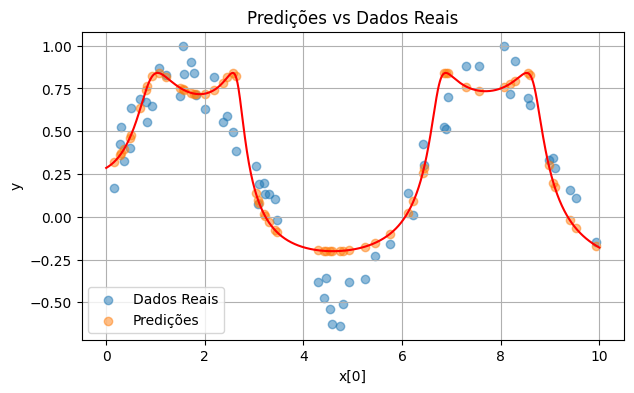

In [6]:
# Teste de generalização, plotar a curva original e a curva predita para o conjunto de teste
def plot_predictions(params, coeffs, x_test, y_test):
    y_pred = mh.forward(x_test, params, coeffs)
    y_pred_complete = mh.forward(jnp.linspace(0,10,1000).reshape(1000,1), params, coeffs)
    plt.figure(figsize=(7, 4))
    plt.scatter(x_test[:, 0], y_test[:, 0], label="Dados Reais", alpha=0.5)
    plt.scatter(x_test[:, 0], y_pred[:, 0], label="Predições", alpha=0.5)
    plt.plot(jnp.linspace(0,10,1000).reshape(1000,1),y_pred_complete, color = "red")
    plt.title("Predições vs Dados Reais")
    plt.xlabel("x[0]")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_predictions(params, coeffs, x_test, y_test)



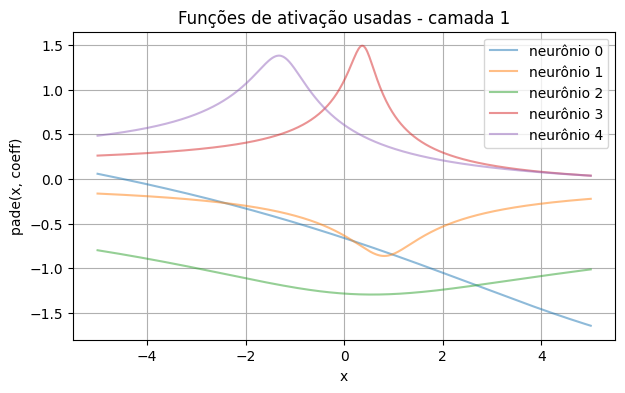

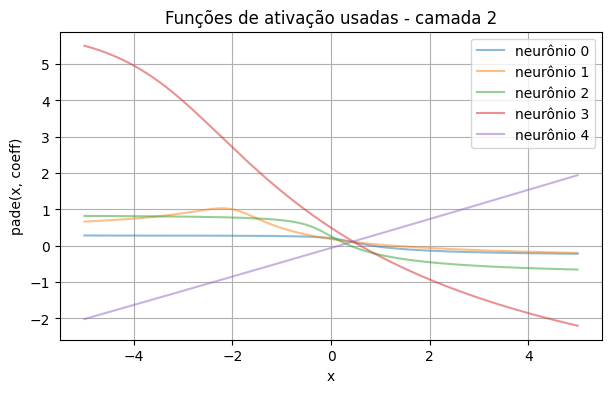

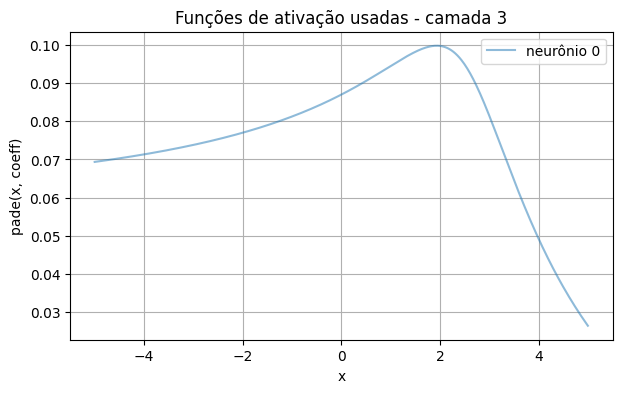

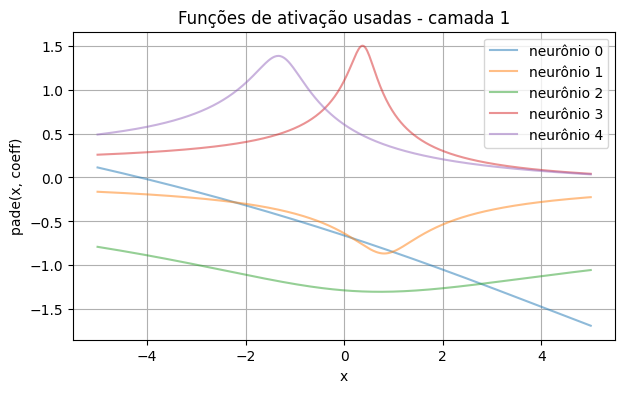

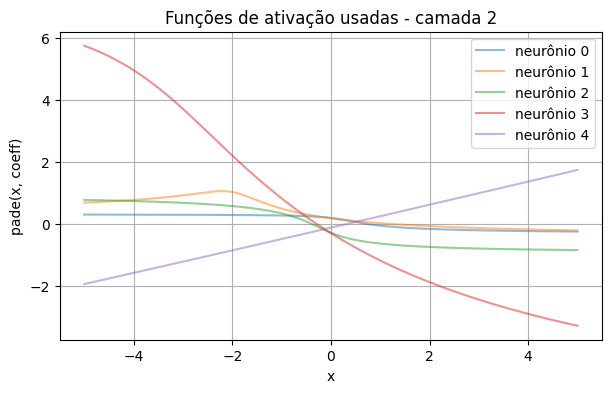

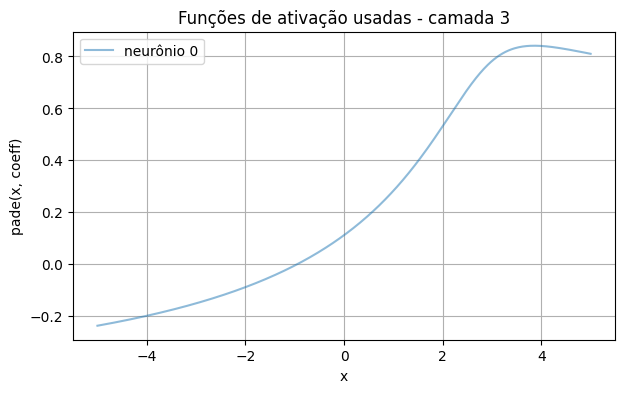

In [8]:
def plot_used_activations(coeffs, x_min=-5, x_max=5, n_points=500):
    xs = jnp.linspace(x_min, x_max, n_points)

    for layer_idx, layer_coeffs in enumerate(coeffs[1:], start=1):
        plt.figure(figsize=(7, 4))

        for neuron_idx, c in enumerate(layer_coeffs):
            ys = paf.s_pade(xs, c)
            plt.plot(xs, ys, label=f"neurônio {neuron_idx}", alpha = 0.5)

        plt.title(f"Funções de ativação usadas - camada {layer_idx}")
        plt.xlabel("x")
        plt.ylabel("pade(x, coeff)")
        plt.legend()
        plt.grid(True)
        plt.show()


plot_used_activations(coeffs_init)
plot_used_activations(coeffs)

In [ ]:


def plot_used_activations(coeffs_old, coeffs_new, x_min=-10, x_max=10, n_points=500):
    xs = jnp.linspace(x_min, x_max, n_points)

    for layer_idx, (layer_old, layer_new) in enumerate(
        zip(coeffs_old, coeffs_new), start=1
    ):
        for neuron_idx, (c_old, c_new) in enumerate(
            zip(layer_old, layer_new)
        ):
            ys_old = paf.s_pade(xs, c_old)
            ys_new = paf.s_pade(xs, c_new)

            plt.figure(figsize=(7, 4))

            plt.plot(xs, ys_old, label="old")
            plt.plot(xs, ys_new, label="new")

            plt.title(
                f"Funções de ativação - camada {layer_idx}, neurônio {neuron_idx}"
            )
            plt.xlabel("x")
            plt.ylabel("pade(x, coeff)")
            plt.legend()
            # plt.xlim(x_min, x_max)
            # plt.ylim(x_min, x_max)
            plt.grid(True)
            plt.show()

plot_used_activations(coeffs_init[1:], coeffs[1:])


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pinn_pau = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_pau_exp3.npz')
pinn_smpaf = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_smPAF_exp3.npz')
pinn_tanh = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_tahn_exp3.npz')

In [8]:
pinn_smpaf['config_json']

array('{"model": "smpaf", "seed": 1, "alpha": 1.0, "nu": 0.003183098861837907, "network_size": [2, 64, 64, 64, 1], "outer_steps": 10000, "inner_steps": 50, "lr_params": 0.0001, "lr_coeffs": 0.0005, "lambda_f": 1.0, "lambda_ic": 5.0, "lambda_bc": 5.0, "kappa": 0.4, "adaptive_update": "first_order_bilevel"}',
      dtype='<U299')

['model_name', 'config_json', 'relative_l2', 'elapsed_seconds', 'x_grid', 't_grid', 'U_reference', 'U_prediction', 'step', 'train_total', 'train_pde', 'train_ic', 'train_bc', 'val_total', 'val_pde', 'val_ic', 'val_bc', 'train_X_f', 'train_X_ic', 'train_y_ic', 'train_X_bc', 'train_y_bc', 'val_X_f', 'val_X_ic', 'val_y_ic', 'val_X_bc', 'val_y_bc', 'param_W_0', 'param_b_0', 'param_W_1', 'param_b_1', 'param_W_2', 'param_b_2', 'param_W_3', 'param_b_3', 'coeffs_0', 'coeffs_1', 'coeffs_2']


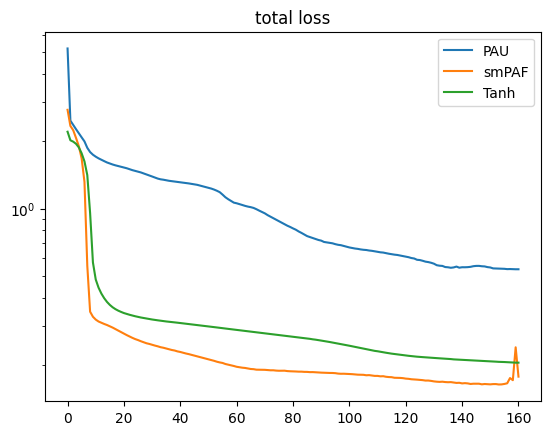

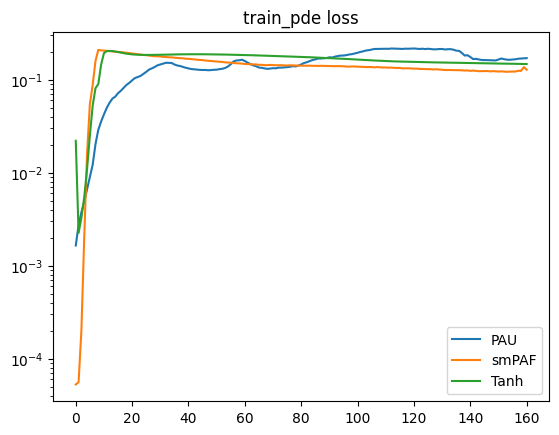

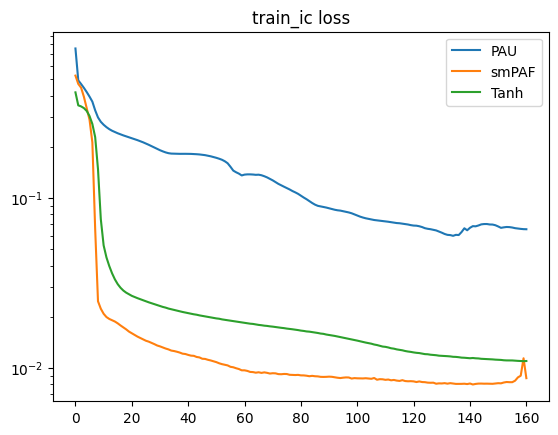

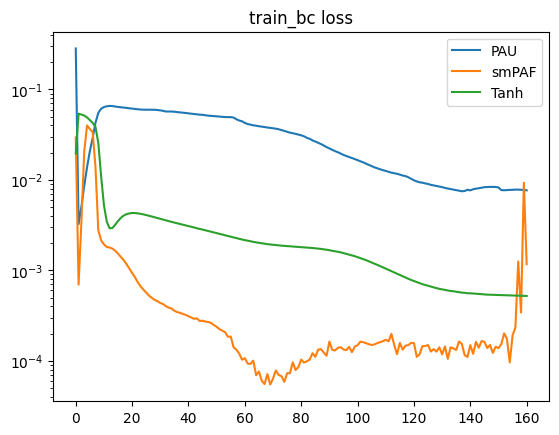

In [3]:
print(pinn_pau.files)

pinn_pau['relative_l2']

plt.title("total loss")
plt.semilogy(pinn_pau['train_total'],label = "PAU")
plt.semilogy(pinn_smpaf['train_total'], label = "smPAF")
plt.semilogy(pinn_tanh['train_total'], label = "Tanh")
plt.legend()
plt.show()

plt.title("train_pde loss")
plt.semilogy(pinn_pau['train_pde'],label = "PAU")
plt.semilogy(pinn_smpaf['train_pde'], label = "smPAF")
plt.semilogy(pinn_tanh['train_pde'], label = "Tanh")
plt.legend()
plt.show()

plt.title("train_ic loss")
plt.semilogy(pinn_pau['train_ic'],label = "PAU")
plt.semilogy(pinn_smpaf['train_ic'], label = "smPAF")
plt.semilogy(pinn_tanh['train_ic'], label = "Tanh")
plt.legend()
plt.show()

plt.title("train_bc loss")
plt.semilogy(pinn_pau['train_bc'],label = "PAU")
plt.semilogy(pinn_smpaf['train_bc'], label = "smPAF")
plt.semilogy(pinn_tanh['train_bc'], label = "Tanh")
plt.legend()
plt.show()




In [7]:
pinn_smpaf0_01 = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_smPAF_exp4.npz')
pinn_smpaf0_1 = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_smPAF_exp5.npz')
pinn_smpaf1 = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_smPAF_exp6.npz')
pinn_smpaf10 = np.load('/home/pcleonardo/pade_AF/pinn_burgers_experiments/results/pinn_smPAF_exp7.npz')


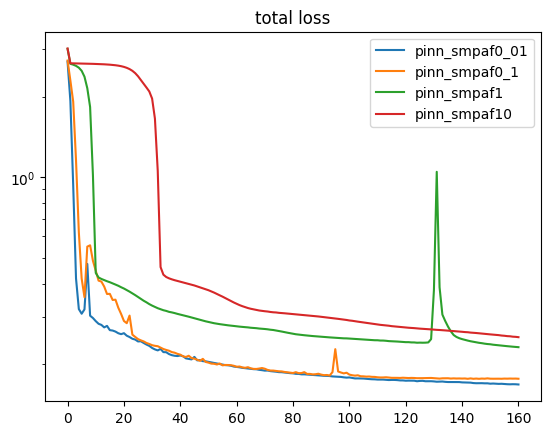

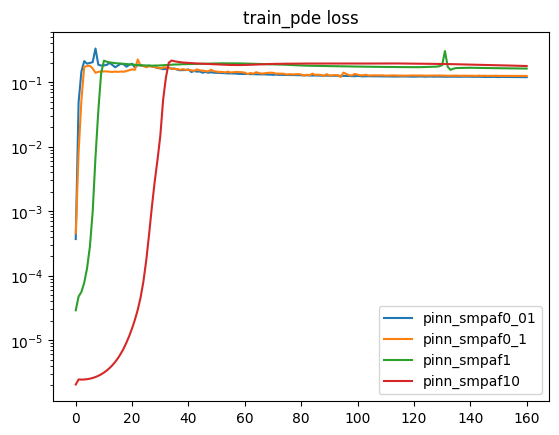

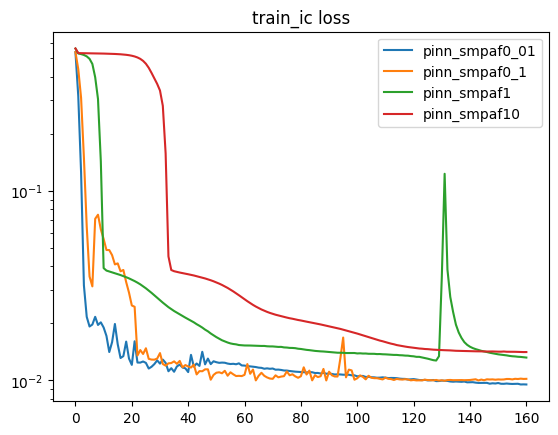

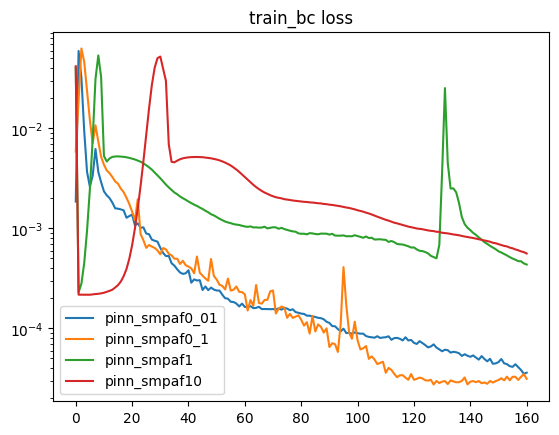

In [8]:

plt.title("total loss")
plt.semilogy(pinn_smpaf0_01['train_total'],label = "pinn_smpaf0_01")
plt.semilogy(pinn_smpaf0_1['train_total'], label = "pinn_smpaf0_1")
plt.semilogy(pinn_smpaf1['train_total'], label = "pinn_smpaf1")
plt.semilogy(pinn_smpaf10['train_total'], label = "pinn_smpaf10")
plt.legend()
plt.show()

plt.title("train_pde loss")
plt.semilogy(pinn_smpaf0_01['train_pde'],label = "pinn_smpaf0_01")
plt.semilogy(pinn_smpaf0_1['train_pde'], label = "pinn_smpaf0_1")
plt.semilogy(pinn_smpaf1['train_pde'], label = "pinn_smpaf1")
plt.semilogy(pinn_smpaf10['train_pde'], label = "pinn_smpaf10")
plt.legend()
plt.show()

plt.title("train_ic loss")
plt.semilogy(pinn_smpaf0_01['train_ic'],label = "pinn_smpaf0_01")
plt.semilogy(pinn_smpaf0_1['train_ic'], label = "pinn_smpaf0_1")
plt.semilogy(pinn_smpaf1['train_ic'], label = "pinn_smpaf1")
plt.semilogy(pinn_smpaf10['train_ic'], label = "pinn_smpaf10")
plt.legend()
plt.show()

plt.title("train_bc loss")
plt.semilogy(pinn_smpaf0_01['train_bc'],label = "pinn_smpaf0_01")
plt.semilogy(pinn_smpaf0_1['train_bc'], label = "pinn_smpaf0_1")
plt.semilogy(pinn_smpaf1['train_bc'], label = "pinn_smpaf1")
plt.semilogy(pinn_smpaf10['train_bc'], label = "pinn_smpaf10")
plt.legend()
plt.show()


